# Location normalisation

Field reports give locations in several different formats: decimal degrees, degrees‑minutes‑seconds, hemisphere letters, and **Indian Grid** eastings and northings. This notebook:

* **Part A – Clean the data:** works out each record's format, converts every location to **WGS84 decimal latitude/longitude**, and flags records that are invalid or wrong.
* **Part B – Analyse:** finds the reports within **25 km of Connaught Place (28.6139, 77.2090)** and explains how the distance is calculated.
* **Part C – Discussion:** how to store and query these records in **Elasticsearch**.

All the maths is written out and implemented by hand with Python's `math` module, so no projection library (such as `pyproj`) is needed. Every formula is checked numerically before it is used.

### Contents
1. Setup and loading the data
2. Part A.1 – Working out each record's format
3. Part A.2 – Decimal and DMS conversion
4. Part A.3 – Indian Grid → WGS84 (projection maths and datum shift)
5. Part A.4 – Checks that the conversion is correct
6. Part A.5 – Normalising every record
7. Part A.6 – Plausibility checks and flags
8. Part B – Distance from Connaught Place
9. Part C – Elasticsearch discussion
10. Summary

## 1. Setup and loading the data

The records arrive as an Elasticsearch search response. Each record sits at `hits.hits[]._source`, so we read the JSON and pull out the `_source` of every hit.

In [1]:
import json, math, re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 6)
pd.set_option("display.max_colwidth", 80)

SRC = Path("Location_Normalisation.json")
if not SRC.exists():                                   # fall back to the original download
    SRC = Path.home() / "Downloads" / "Location_Normalisation.json"

raw = json.loads(SRC.read_text(encoding="utf-8"))
records = [hit["_source"] for hit in raw["hits"]["hits"]]

print(f"Loaded {len(records)} records (response says total = {raw['hits']['total']['value']})")
pd.DataFrame(records)

Loaded 9 records (response says total = 9)


,id,place,location
0,L1,"Connaught Place, New Delhi","28.6139, 77.2090"
1,L2,Noida Sector 18,IIA E 3068101 N 1203024
2,L3,Jaipur,"26°54'45""N 75°47'14""E"
3,L4,"Karol Bagh, New Delhi","77.1909, 28.6519"
4,L5,Unknown,"0, 0"
5,L6,Rohtak,None
6,L7,Meerut,"28.9845 N, 77.7064 E"
7,L8,Agra,IIB E 3140017 N 1050679
8,L9,Sonipat,IIA E 3037105 N 1249178


## 2. Part A.1 – Working out each record's format

Each format has its own regular expression. They are tried from most specific to least specific, so a grid reference is never mistaken for a pair of decimal numbers.

| Format | Example | Pattern idea |
|---|---|---|
| `grid` | `IIA E 3068101 N 1203024` | zone code (`I`, `IIA`, `IIB`, …), then `E <metres>` and `N <metres>` |
| `dms` | `26°54'45"N 75°47'14"E` | `d° m' s"` followed by a hemisphere letter, twice |
| `hemisphere` | `28.9845 N, 77.7064 E` | decimal number + hemisphere letter, twice |
| `decimal_pair` | `28.6139, 77.2090` | two signed decimals separated by a comma. **The order (lat,lon or lon,lat) is not certain yet** – it is checked in A.6 |
| `missing` | `null` / empty | no value |

In [2]:
NUM = r"[-+]?\d+(?:\.\d+)?"

PATTERNS = {
    "grid": re.compile(
        rf"^\s*(?P<zone>[IV]+[AB]?)\s+E\s*(?P<E>{NUM})\s+N\s*(?P<N>{NUM})\s*$", re.I),
    "dms": re.compile(
        # \x27 is ' (minutes) and \x22 is " (seconds)
        r"^\s*(?P<lat_d>\d+)\s*°\s*(?P<lat_m>\d+)\s*\x27\s*(?P<lat_s>\d+(?:\.\d+)?)\s*\x22\s*(?P<lat_h>[NS])"
        r"\s*,?\s*(?P<lon_d>\d+)\s*°\s*(?P<lon_m>\d+)\s*\x27\s*(?P<lon_s>\d+(?:\.\d+)?)\s*\x22\s*(?P<lon_h>[EW])\s*$",
        re.I),
    "hemisphere": re.compile(
        rf"^\s*(?P<lat>{NUM})\s*(?P<lat_h>[NS])\s*,\s*(?P<lon>{NUM})\s*(?P<lon_h>[EW])\s*$", re.I),
    "decimal_pair": re.compile(
        rf"^\s*(?P<a>{NUM})\s*,\s*(?P<b>{NUM})\s*$"),
}

def detect_format(value):
    # Return (format_name, captured groups) for a raw location string.
    if value is None or str(value).strip() == "":
        return "missing", {}
    for name, pattern in PATTERNS.items():
        m = pattern.match(str(value))
        if m:
            return name, m.groupdict()
    return "unrecognised", {}

pd.DataFrame(
    [{"id": r["id"], "location": r["location"], "format": detect_format(r["location"])[0]} for r in records]
)

,id,location,format
0,L1,"28.6139, 77.2090",decimal_pair
1,L2,IIA E 3068101 N 1203024,grid
2,L3,"26°54'45""N 75°47'14""E",dms
3,L4,"77.1909, 28.6519",decimal_pair
4,L5,"0, 0",decimal_pair
5,L6,None,missing
6,L7,"28.9845 N, 77.7064 E",hemisphere
7,L8,IIB E 3140017 N 1050679,grid
8,L9,IIA E 3037105 N 1249178,grid


## 3. Part A.2 – Decimal and DMS conversion

**Degrees–minutes–seconds.** A degree has 60 minutes and a minute has 60 seconds, so

$$\text{decimal} = d + \frac{m}{60} + \frac{s}{3600},$$

and the value is made negative for the **S** and **W** hemispheres.

Worked example (Jaipur, latitude): $26 + \tfrac{54}{60} + \tfrac{45}{3600} = 26 + 0.9 + 0.0125 = 26.9125^\circ$ N.

**Hemisphere letters** (`28.9845 N`) work the same way: take the number and make it negative for S or W.

**Plain decimal pairs** (`a, b`) need no conversion, but we don't yet know whether they are `lat, lon` or `lon, lat`. The usual convention is `lat, lon`, and A.6 checks it.

In [3]:
def signed(value, hemi):
    return -float(value) if hemi.upper() in ("S", "W") else float(value)

def dms_to_decimal(d, m, s, hemi):
    return signed(float(d) + float(m) / 60 + float(s) / 3600, hemi)

print("Jaipur lat :", dms_to_decimal(26, 54, 45, "N"))
print("Jaipur lon :", dms_to_decimal(75, 47, 14, "E"))

Jaipur lat : 26.912499999999998
Jaipur lon : 75.78722222222223


## 4. Part A.3 – Indian Grid → WGS84

A grid reference is a point on a **flat map**, measured in metres. Turning it into WGS84 latitude/longitude takes two separate steps:

```
(E, N) metres ──inverse LCC projection──▶ (φ, λ) on Everest 1956 ──datum shift──▶ (φ, λ) on WGS84
```

### 4.1 Parameters (from the brief)

| Parameter | Value |
|---|---|
| Projection | Lambert Conformal Conic, 1 standard parallel (EPSG method 9801) |
| Zone IIA | latitude of origin $\varphi_0 = 26^\circ$N, central meridian $\lambda_0 = 74^\circ$E |
| Zone IIB | latitude of origin $\varphi_0 = 26^\circ$N, central meridian $\lambda_0 = 90^\circ$E |
| Scale factor | $k_0 = 0.99878641$ |
| False easting / northing | $FE = 2\,743\,196.4$ m, $FN = 914\,398.8$ m |
| Ellipsoid | Everest 1956: $a = 6\,377\,301.243$ m, $1/f = 300.8017$ |
| Datum shift (Indian → WGS84) | $\Delta X = +295$ m, $\Delta Y = +736$ m, $\Delta Z = +257$ m |

### 4.2 Ellipsoid quantities

From the flattening $f$, the eccentricity is

$$e^2 = f(2 - f), \qquad e = \sqrt{e^2}.$$

### 4.3 Lambert Conformal Conic (1SP) – the forward direction

The projection wraps a cone around the Earth so that it touches along the standard parallel $\varphi_0$. Two helper functions of latitude:

$$m(\varphi) = \frac{\cos\varphi}{\sqrt{1 - e^2\sin^2\varphi}}, \qquad
t(\varphi) = \frac{\tan\!\left(\frac{\pi}{4} - \frac{\varphi}{2}\right)}{\left(\dfrac{1 - e\sin\varphi}{1 + e\sin\varphi}\right)^{e/2}}$$

Constants of the cone:

$$n = \sin\varphi_0, \qquad F = \frac{m(\varphi_0)}{n\,t(\varphi_0)^n}, \qquad r_0 = a\,F\,t(\varphi_0)^n\,k_0$$

A point $(\varphi,\lambda)$ maps to a radius $r$ (its distance from the cone's apex) and an angle $\theta$:

$$r = a\,F\,t(\varphi)^n\,k_0, \qquad \theta = n(\lambda - \lambda_0)$$

$$E = FE + r\sin\theta, \qquad N = FN + r_0 - r\cos\theta$$

### 4.4 The inverse direction (what we need)

Work backwards from $(E, N)$:

$$r' = \operatorname{sign}(n)\sqrt{(E - FE)^2 + \big(r_0 - (N - FN)\big)^2}, \qquad
\theta' = \operatorname{atan2}\!\big(E - FE,\; r_0 - (N - FN)\big)$$

$$t' = \left(\frac{r'}{a\,k_0\,F}\right)^{1/n}, \qquad \lambda = \frac{\theta'}{n} + \lambda_0$$

Latitude has no closed form, so we iterate, starting from $\varphi = \frac{\pi}{2} - 2\arctan t'$:

$$\varphi_{i+1} = \frac{\pi}{2} - 2\arctan\!\left[t'\left(\frac{1 - e\sin\varphi_i}{1 + e\sin\varphi_i}\right)^{e/2}\right]$$

This converges to better than $10^{-12}$ rad (well under a millimetre) within a few iterations.

In [4]:
# --- constants from the brief -------------------------------------------------
EVEREST_1956 = {"a": 6377301.243, "inv_f": 300.8017}
WGS84        = {"a": 6378137.0,   "inv_f": 298.257223563}

INDIAN_GRID_ZONES = {
    "IIA": {"lat0": 26.0, "lon0": 74.0},
    "IIB": {"lat0": 26.0, "lon0": 90.0},
}
K0, FE, FN = 0.99878641, 2743196.4, 914398.8
DATUM_SHIFT = (295.0, 736.0, 257.0)          # Indian -> WGS84, metres

def ellipsoid(a, inv_f):
    f = 1 / inv_f
    e2 = f * (2 - f)
    return a, f, e2, math.sqrt(e2)

def _m(phi, e):
    return math.cos(phi) / math.sqrt(1 - (e * math.sin(phi)) ** 2)

def _t(phi, e):
    es = e * math.sin(phi)
    return math.tan(math.pi / 4 - phi / 2) / ((1 - es) / (1 + es)) ** (e / 2)

def lcc_constants(zone, ell=EVEREST_1956):
    a, f, e2, e = ellipsoid(**ell)
    z = INDIAN_GRID_ZONES[zone]
    phi0, lam0 = math.radians(z["lat0"]), math.radians(z["lon0"])
    n  = math.sin(phi0)
    F  = _m(phi0, e) / (n * _t(phi0, e) ** n)
    r0 = a * F * _t(phi0, e) ** n * K0
    return {"a": a, "e": e, "n": n, "F": F, "r0": r0, "lam0": lam0}

for z in INDIAN_GRID_ZONES:
    c = lcc_constants(z)
    print(f"{z}: n = {c['n']:.9f}  F = {c['F']:.9f}  r0 = {c['r0']:,.3f} m")

IIA: n = 0.438371147  F = 2.518032247  r0 = 13,067,874.341 m
IIB: n = 0.438371147  F = 2.518032247  r0 = 13,067,874.341 m


In [5]:
def lcc_forward(lat, lon, zone):
    # Everest-1956 geographic (deg) -> Indian Grid (E, N) metres.
    c = lcc_constants(zone)
    phi, lam = math.radians(lat), math.radians(lon)
    r = c["a"] * c["F"] * _t(phi, c["e"]) ** c["n"] * K0
    theta = c["n"] * (lam - c["lam0"])
    return FE + r * math.sin(theta), FN + c["r0"] - r * math.cos(theta)

def lcc_inverse(E, N, zone, tol=1e-12, max_iter=50):
    # Indian Grid (E, N) metres -> Everest-1956 geographic (deg).
    c = lcc_constants(zone)
    e, n = c["e"], c["n"]
    dx, dy = E - FE, c["r0"] - (N - FN)
    r = math.copysign(math.hypot(dx, dy), n)
    theta = math.atan2(dx, dy)
    t = (r / (c["a"] * K0 * c["F"])) ** (1 / n)

    phi = math.pi / 2 - 2 * math.atan(t)
    for _ in range(max_iter):
        es = e * math.sin(phi)
        phi_next = math.pi / 2 - 2 * math.atan(t * ((1 - es) / (1 + es)) ** (e / 2))
        if abs(phi_next - phi) < tol:
            phi = phi_next
            break
        phi = phi_next
    lam = theta / n + c["lam0"]
    return math.degrees(phi), math.degrees(lam)

### 4.5 Datum shift: Everest 1956 → WGS84

The latitude and longitude from 4.4 belong to the **Indian datum**, which uses the Everest ellipsoid in a different position from WGS84. The brief gives a **3‑parameter (geocentric translation) shift**, which is applied to 3D Earth‑centred, Earth‑fixed (ECEF) coordinates:

**Step 1 – geographic → ECEF on Everest.** With prime‑vertical radius $\nu = \dfrac{a}{\sqrt{1 - e^2\sin^2\varphi}}$ and height $h$ (taken as 0, since reports carry no height):

$$X = (\nu + h)\cos\varphi\cos\lambda,\quad Y = (\nu + h)\cos\varphi\sin\lambda,\quad Z = \big(\nu(1 - e^2) + h\big)\sin\varphi$$

**Step 2 – translate:**

$$X' = X + \Delta X,\quad Y' = Y + \Delta Y,\quad Z' = Z + \Delta Z$$

**Step 3 – ECEF → geographic on WGS84** (iterative):

$$\lambda = \operatorname{atan2}(Y', X'),\qquad p = \sqrt{X'^2 + Y'^2}$$

$$\text{start } \varphi = \operatorname{atan2}\!\big(Z',\, p(1 - e^2)\big),\ \text{ then repeat: }\ \nu = \frac{a}{\sqrt{1 - e^2\sin^2\varphi}},\ \ h = \frac{p}{\cos\varphi} - \nu,\ \ \varphi = \operatorname{atan2}\!\left(Z',\ p\Big(1 - e^2\frac{\nu}{\nu + h}\Big)\right)$$

using the WGS84 $a$ and $e^2$. The new height $h$ is a by‑product and is thrown away.

In [6]:
def geodetic_to_ecef(lat, lon, h, ell):
    a, f, e2, e = ellipsoid(**ell)
    phi, lam = math.radians(lat), math.radians(lon)
    nu = a / math.sqrt(1 - e2 * math.sin(phi) ** 2)
    return ((nu + h) * math.cos(phi) * math.cos(lam),
            (nu + h) * math.cos(phi) * math.sin(lam),
            (nu * (1 - e2) + h) * math.sin(phi))

def ecef_to_geodetic(X, Y, Z, ell, tol=1e-13, max_iter=50):
    a, f, e2, e = ellipsoid(**ell)
    lam = math.atan2(Y, X)
    p = math.hypot(X, Y)
    phi = math.atan2(Z, p * (1 - e2))
    h = 0.0
    for _ in range(max_iter):
        nu = a / math.sqrt(1 - e2 * math.sin(phi) ** 2)
        h = p / math.cos(phi) - nu
        phi_next = math.atan2(Z, p * (1 - e2 * nu / (nu + h)))
        if abs(phi_next - phi) < tol:
            phi = phi_next
            break
        phi = phi_next
    return math.degrees(phi), math.degrees(lam), h

def everest_to_wgs84(lat, lon, h=0.0):
    X, Y, Z = geodetic_to_ecef(lat, lon, h, EVEREST_1956)
    dX, dY, dZ = DATUM_SHIFT
    return ecef_to_geodetic(X + dX, Y + dY, Z + dZ, WGS84)

def wgs84_to_everest(lat, lon, h=0.0):
    # Reverse shift, used only to test the round trip.
    X, Y, Z = geodetic_to_ecef(lat, lon, h, WGS84)
    dX, dY, dZ = DATUM_SHIFT
    return ecef_to_geodetic(X - dX, Y - dY, Z - dZ, EVEREST_1956)

def grid_to_wgs84(zone, E, N):
    lat_ev, lon_ev = lcc_inverse(E, N, zone)
    lat, lon, _h = everest_to_wgs84(lat_ev, lon_ev)
    return lat, lon

## 5. Part A.4 – Checks that the conversion is correct

Before trusting the converter we run three tests:

1. **The grid origin.** $(E, N) = (FE, FN)$ must come back as exactly $(26^\circ\text{N}, \lambda_0)$ for each zone.
2. **Projection round trip.** For each grid reference, inverse then forward must reproduce $(E, N)$ to well under a millimetre.
3. **Full round trip.** WGS84 → Everest → grid must reproduce the original $(E, N)$. This tests the datum shift as well. The shift changes the ellipsoidal height slightly (`wgs84_h_m`), so that height has to be passed back for the trip to close exactly. Dropping it causes millimetre‑level errors, which is harmless here, but the test is meant to be exact.

We also measure how far the datum shift moves each point, to show why the shift can't be skipped.

In [7]:
for zone, z in INDIAN_GRID_ZONES.items():
    lat, lon = lcc_inverse(FE, FN, zone)
    print(f"Origin {zone}: ({lat:.12f}, {lon:.12f})  expected ({z['lat0']}, {z['lon0']})")
    assert abs(lat - z["lat0"]) < 1e-10 and abs(lon - z["lon0"]) < 1e-10

Origin IIA: (26.000000000000, 74.000000000000)  expected (26.0, 74.0)
Origin IIB: (26.000000000000, 90.000000000000)  expected (26.0, 90.0)


In [8]:
grid_records = [(r["id"], *detect_format(r["location"])) for r in records]
grid_records = [(rid, g) for rid, fmt, g in grid_records if fmt == "grid"]

rows = []
for rid, g in grid_records:
    zone, E, N = g["zone"].upper(), float(g["E"]), float(g["N"])
    lat_ev, lon_ev = lcc_inverse(E, N, zone)
    E1, N1 = lcc_forward(lat_ev, lon_ev, zone)                    # test 2
    lat_w, lon_w, h_w = everest_to_wgs84(lat_ev, lon_ev)
    lat_back, lon_back, _ = wgs84_to_everest(lat_w, lon_w, h_w)   # test 3 (carry h back)
    E2, N2 = lcc_forward(lat_back, lon_back, zone)
    rows.append({
        "id": rid, "zone": zone,
        "everest_lat": lat_ev, "everest_lon": lon_ev,
        "wgs84_lat": lat_w, "wgs84_lon": lon_w, "wgs84_h_m": h_w,
        "proj_roundtrip_mm": 1000 * math.hypot(E1 - E, N1 - N),
        "full_roundtrip_mm": 1000 * math.hypot(E2 - E, N2 - N),
    })
checks = pd.DataFrame(rows)
assert (checks["proj_roundtrip_mm"] < 1).all() and (checks["full_roundtrip_mm"] < 1).all()
checks

,id,zone,everest_lat,everest_lon,wgs84_lat,wgs84_lon,wgs84_h_m,proj_roundtrip_mm,full_roundtrip_mm
0,L2,IIA,28.569955,77.322291,28.570003,77.321000,16.529385,0.000002,0.000003
1,L8,IIB,27.176512,94.009466,27.176978,94.005977,-45.356613,0.000000,0.000002
2,L9,IIA,28.993098,77.016351,28.993102,77.015098,17.132174,0.000004,0.000002


Both round trips come back to within a tiny fraction of a millimetre, so the forward and inverse formulas agree. The size of the datum shift is measured in the next cell, once the distance function exists.

### 5.1 Distance on the Earth (needed for the checks and for Part B)

**Haversine (great‑circle) distance** treats the Earth as a sphere with mean radius $R = 6371.0088$ km:

$$a = \sin^2\!\frac{\Delta\varphi}{2} + \cos\varphi_1\cos\varphi_2\sin^2\!\frac{\Delta\lambda}{2}, \qquad d = 2R\,\arcsin\sqrt{a}$$

It is the shortest path over the surface. It is not the same as straight‑line (Euclidean) distance on raw degrees, which is wrong because one degree of longitude is only $111.3\cos\varphi$ km long. At 28.6°N that is about 97.7 km, compared with about 111 km for a degree of latitude.

**Vincenty's inverse formula** solves the same problem on the WGS84 **ellipsoid** and is accurate to about a millimetre. We use it as an independent check on haversine.

In [9]:
R_EARTH_KM = 6371.0088          # IUGG mean radius

def haversine_km(lat1, lon1, lat2, lon2):
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi, dlam = phi2 - phi1, math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlam / 2) ** 2
    return 2 * R_EARTH_KM * math.asin(math.sqrt(a))

def vincenty_km(lat1, lon1, lat2, lon2, ell=WGS84, tol=1e-12, max_iter=200):
    a, f, e2, e = ellipsoid(**ell)
    b = a * (1 - f)
    if (lat1, lon1) == (lat2, lon2):
        return 0.0
    L = math.radians(lon2 - lon1)
    U1 = math.atan((1 - f) * math.tan(math.radians(lat1)))
    U2 = math.atan((1 - f) * math.tan(math.radians(lat2)))
    sinU1, cosU1, sinU2, cosU2 = math.sin(U1), math.cos(U1), math.sin(U2), math.cos(U2)
    lam = L
    for _ in range(max_iter):
        sin_lam, cos_lam = math.sin(lam), math.cos(lam)
        sin_sigma = math.hypot(cosU2 * sin_lam, cosU1 * sinU2 - sinU1 * cosU2 * cos_lam)
        cos_sigma = sinU1 * sinU2 + cosU1 * cosU2 * cos_lam
        sigma = math.atan2(sin_sigma, cos_sigma)
        sin_alpha = cosU1 * cosU2 * sin_lam / sin_sigma
        cos2_alpha = 1 - sin_alpha ** 2
        cos_2sm = cos_sigma - 2 * sinU1 * sinU2 / cos2_alpha if cos2_alpha else 0.0
        C = f / 16 * cos2_alpha * (4 + f * (4 - 3 * cos2_alpha))
        lam_prev = lam
        lam = L + (1 - C) * f * sin_alpha * (
            sigma + C * sin_sigma * (cos_2sm + C * cos_sigma * (-1 + 2 * cos_2sm ** 2)))
        if abs(lam - lam_prev) < tol:
            break
    u2 = cos2_alpha * (a ** 2 - b ** 2) / b ** 2
    A = 1 + u2 / 16384 * (4096 + u2 * (-768 + u2 * (320 - 175 * u2)))
    B = u2 / 1024 * (256 + u2 * (-128 + u2 * (74 - 47 * u2)))
    d_sigma = B * sin_sigma * (cos_2sm + B / 4 * (cos_sigma * (-1 + 2 * cos_2sm ** 2)
              - B / 6 * cos_2sm * (-3 + 4 * sin_sigma ** 2) * (-3 + 4 * cos_2sm ** 2)))
    return b * A * (sigma - d_sigma) / 1000

checks["datum_shift_m"] = [
    1000 * vincenty_km(r.everest_lat, r.everest_lon, r.wgs84_lat, r.wgs84_lon) for r in checks.itertuples()]
checks[["id", "zone", "everest_lat", "everest_lon", "wgs84_lat", "wgs84_lon", "datum_shift_m"]]

,id,zone,everest_lat,everest_lon,wgs84_lat,wgs84_lon,datum_shift_m
0,L2,IIA,28.569955,77.322291,28.570003,77.321000,126.393486
1,L8,IIB,27.176512,94.009466,27.176978,94.005977,349.584066
2,L9,IIA,28.993098,77.016351,28.993102,77.015098,122.099512


The datum shift moves each point by **roughly 120–350 m** (see `datum_shift_m`; it grows the further a point is from where the Indian datum was fitted). That makes no difference to a 25 km search, but it is far too large to ignore for mapping, so it is always applied.

## 6. Part A.5 – Normalising every record

`normalise()` sends each record to the right converter. The original string is always kept in `raw`, so any converted value can be traced back to the source. At this stage a `decimal_pair` is read as `lat, lon`, the usual convention. A.6 then checks that assumption.

In [10]:
def normalise(rec):
    fmt, g = detect_format(rec["location"])
    out = {"id": rec["id"], "place": rec["place"], "raw": rec["location"], "format": fmt,
           "zone": None, "lat": None, "lon": None, "status": "ok", "notes": []}

    if fmt == "missing":
        out["status"] = "invalid"
        out["notes"].append("No location supplied (null).")
    elif fmt == "unrecognised":
        out["status"] = "invalid"
        out["notes"].append("Location string does not match any known format.")
    elif fmt == "grid":
        zone = g["zone"].upper()
        out["zone"] = zone
        if zone not in INDIAN_GRID_ZONES:
            out["status"] = "invalid"
            out["notes"].append(f"Unknown Indian Grid zone '{zone}'.")
        else:
            out["lat"], out["lon"] = grid_to_wgs84(zone, float(g["E"]), float(g["N"]))
    elif fmt == "dms":
        out["lat"] = dms_to_decimal(g["lat_d"], g["lat_m"], g["lat_s"], g["lat_h"])
        out["lon"] = dms_to_decimal(g["lon_d"], g["lon_m"], g["lon_s"], g["lon_h"])
    elif fmt == "hemisphere":
        out["lat"] = signed(g["lat"], g["lat_h"])
        out["lon"] = signed(g["lon"], g["lon_h"])
    elif fmt == "decimal_pair":
        out["lat"], out["lon"] = float(g["a"]), float(g["b"])
    return out

converted = [normalise(r) for r in records]
pd.DataFrame(converted).drop(columns="notes")

,id,place,raw,format,zone,lat,lon,status
0,L1,"Connaught Place, New Delhi","28.6139, 77.2090",decimal_pair,None,28.613900,77.209000,ok
1,L2,Noida Sector 18,IIA E 3068101 N 1203024,grid,IIA,28.570003,77.321000,ok
2,L3,Jaipur,"26°54'45""N 75°47'14""E",dms,None,26.912500,75.787222,ok
3,L4,"Karol Bagh, New Delhi","77.1909, 28.6519",decimal_pair,None,77.190900,28.651900,ok
4,L5,Unknown,"0, 0",decimal_pair,None,0.000000,0.000000,ok
5,L6,Rohtak,None,missing,None,NaN,NaN,invalid
6,L7,Meerut,"28.9845 N, 77.7064 E",hemisphere,None,28.984500,77.706400,ok
7,L8,Agra,IIB E 3140017 N 1050679,grid,IIB,27.176978,94.005977,ok
8,L9,Sonipat,IIA E 3037105 N 1249178,grid,IIA,28.993102,77.015098,ok


## 7. Part A.6 – Plausibility checks and flags

A coordinate can be perfectly well‑formed and still be wrong. Each converted point goes through these rules in order:

| # | Rule | Catches |
|---|---|---|
| 1 | **Range:** $-90 \le \text{lat} \le 90$, $-180 \le \text{lon} \le 180$ | impossible values |
| 2 | **Null Island:** `(0, 0)` is a common placeholder for "unknown" (it is in the Gulf of Guinea) | L5 |
| 3 | **Axis order:** if the point is outside India but **swapping** lat/lon puts it inside, the pair was written `lon, lat` → swap and flag as *corrected* | L4 |
| 4 | **Region:** the point must be inside a rough India bounding box (6–37.5°N, 68–97.5°E) | gross errors |
| 5 | **Place‑name check:** compare with the approximate known centre of the named place. If it is more than 15 km away, flag it. For grid references, also try the **other zone**, and if that one matches, correct it and flag as *corrected* | L8 (wrong zone) |

The reference coordinates for rule 5 are approximate city/locality centres, taken from public gazetteers. They are only used as a sanity check, never as the reported value.

**Why rule 5 is needed:** L8 converted as zone IIB lands at about 94°E. That is still *inside* India (Assam/Arunachal), so rules 1–4 don't catch it. Only checking it against the expected location shows the error.

In [11]:
INDIA_BBOX = {"lat": (6.0, 37.5), "lon": (68.0, 97.5)}
MATCH_TOLERANCE_KM = 15

REFERENCE = {   # approximate centres, used only for plausibility checks
    "Connaught Place, New Delhi": (28.6315, 77.2167),
    "Noida Sector 18":            (28.5700, 77.3260),
    "Jaipur":                     (26.9124, 75.7873),
    "Karol Bagh, New Delhi":      (28.6519, 77.1909),
    "Rohtak":                     (28.8955, 76.6066),
    "Meerut":                     (28.9845, 77.7064),
    "Agra":                       (27.1767, 78.0081),
    "Sonipat":                    (28.9931, 77.0151),
}

def in_india(lat, lon):
    return (INDIA_BBOX["lat"][0] <= lat <= INDIA_BBOX["lat"][1]
            and INDIA_BBOX["lon"][0] <= lon <= INDIA_BBOX["lon"][1])

def validate(rec):
    rec = {**rec, "notes": list(rec["notes"])}
    if rec["lat"] is None:
        return rec
    lat, lon = rec["lat"], rec["lon"]

    # 1. range
    if not (-90 <= lat <= 90 and -180 <= lon <= 180):
        if -90 <= lon <= 90 and in_india(lon, lat):
            pass                                   # handled by rule 3
        else:
            rec.update(status="invalid", lat=None, lon=None)
            rec["notes"].append(f"Out of range ({lat}, {lon}).")
            return rec

    # 2. null island
    if lat == 0 and lon == 0:
        rec.update(status="invalid", lat=None, lon=None)
        rec["notes"].append("(0, 0) is a placeholder ('Null Island', Gulf of Guinea), not a real location.")
        return rec

    # 3. axis order
    if not in_india(lat, lon) and in_india(lon, lat):
        rec.update(lat=lon, lon=lat, status="corrected")
        rec["notes"].append(f"Written as lon,lat: ({lat}, {lon}) read as lat,lon would be at latitude {lat}°; "
                            "swapped.")
        lat, lon = rec["lat"], rec["lon"]

    # 4. region
    if not in_india(lat, lon):
        rec["status"] = "suspect"
        rec["notes"].append("Outside the India bounding box.")

    # 5. place-name check
    ref = REFERENCE.get(rec["place"])
    if ref:
        off = haversine_km(lat, lon, *ref)
        rec["ref_offset_km"] = off
        if off > MATCH_TOLERANCE_KM:
            fixed = False
            if rec["format"] == "grid":
                _, g = detect_format(rec["raw"])
                for alt in INDIAN_GRID_ZONES:
                    if alt == rec["zone"]:
                        continue
                    alat, alon = grid_to_wgs84(alt, float(g["E"]), float(g["N"]))
                    alt_off = haversine_km(alat, alon, *ref)
                    if alt_off <= MATCH_TOLERANCE_KM:
                        rec["notes"].append(
                            f"As zone {rec['zone']} it lands at ({lat:.4f}, {lon:.4f}), {off:,.0f} km from "
                            f"{rec['place']}. As zone {alt} it is {alt_off:.2f} km away → zone label is wrong; "
                            f"converted as {alt}.")
                        rec.update(lat=alat, lon=alon, zone=alt, status="corrected", ref_offset_km=alt_off)
                        fixed = True
                        break
            if not fixed:
                rec["status"] = "suspect"
                rec["notes"].append(f"{off:,.1f} km from the expected location of {rec['place']}.")
    return rec

clean = pd.DataFrame([validate(r) for r in converted])
clean["notes"] = clean["notes"].apply(" ".join)
clean[["id", "place", "raw", "format", "zone", "lat", "lon", "status", "ref_offset_km", "notes"]]

,id,place,raw,format,zone,lat,lon,status,ref_offset_km,notes
0,L1,"Connaught Place, New Delhi","28.6139, 77.2090",decimal_pair,None,28.613900,77.209000,ok,2.096386,
1,L2,Noida Sector 18,IIA E 3068101 N 1203024,grid,IIA,28.570003,77.321000,ok,0.488265,
2,L3,Jaipur,"26°54'45""N 75°47'14""E",dms,None,26.912500,75.787222,ok,0.013532,
3,L4,"Karol Bagh, New Delhi","77.1909, 28.6519",decimal_pair,None,28.651900,77.190900,corrected,0.000000,"Written as lon,lat: (77.1909, 28.6519) read as lat,lon would be at latitude ..."
4,L5,Unknown,"0, 0",decimal_pair,None,NaN,NaN,invalid,NaN,"(0, 0) is a placeholder ('Null Island', Gulf of Guinea), not a real location."
5,L6,Rohtak,None,missing,None,NaN,NaN,invalid,NaN,No location supplied (null).
6,L7,Meerut,"28.9845 N, 77.7064 E",hemisphere,None,28.984500,77.706400,ok,0.000000,
7,L8,Agra,IIB E 3140017 N 1050679,grid,IIA,27.176700,78.008097,corrected,0.000275,"As zone IIB it lands at (27.1770, 94.0060), 1,581 km from Agra. As zone IIA ..."
8,L9,Sonipat,IIA E 3037105 N 1249178,grid,IIA,28.993102,77.015098,ok,0.000319,


### Part A result

| ID | Place | Format | Result | Flag |
|---|---|---|---|---|
| L1 | Connaught Place | decimal lat,lon | as given | ok |
| L2 | Noida Sector 18 | Indian Grid IIA | converted | ok |
| L3 | Jaipur | DMS | converted | ok |
| L4 | Karol Bagh | decimal, **written lon,lat** | swapped | **corrected**: read as lat,lon it would put Karol Bagh at latitude 77°, in the Arctic |
| L5 | Unknown | decimal | – | **invalid**: `(0, 0)` is a placeholder, and the place is "Unknown" too |
| L6 | Rohtak | missing | – | **invalid**: no location. Keep the record and leave the location empty; don't guess one |
| L7 | Meerut | hemisphere letters | converted | ok |
| L8 | Agra | Indian Grid, **labelled IIB** | converted as IIA | **corrected**: as IIB it lands about 1,600 km east, in Assam/Arunachal. As IIA it matches Agra almost exactly. The zone label is wrong |
| L9 | Sonipat | Indian Grid IIA | converted | ok |

The *corrected* records keep their original string, so the correction can be reviewed later.

## 8. Part B – Reports within 25 km of Connaught Place

**Method.** For every record with a valid location, compute the **haversine** great‑circle distance (section 5.1) from the reference point $(28.6139, 77.2090)$ and keep those with $d \le 25$ km.

**Why haversine is accurate enough.** A sphere is a simplification of the Earth's shape. The cell below compares haversine with Vincenty's ellipsoidal distance for every record. The difference is at most about 0.25% (`diff_m`), which is about 60 m at 25 km. It can only change the answer for a point within about 100 m of the 25 km line. Here the nearest one outside the circle (Sonipat) is 21 km beyond it, so the result is not borderline. If it were, Vincenty would be the method to trust.

In [12]:
CP = (28.6139, 77.2090)
RADIUS_KM = 25

valid = clean[clean["lat"].notna()].copy()
valid["haversine_km"] = [haversine_km(*CP, la, lo) for la, lo in zip(valid["lat"], valid["lon"])]
valid["vincenty_km"]  = [vincenty_km(*CP, la, lo)  for la, lo in zip(valid["lat"], valid["lon"])]
valid["diff_m"] = 1000 * (valid["haversine_km"] - valid["vincenty_km"])
valid["within_25km"] = valid["haversine_km"] <= RADIUS_KM

valid.sort_values("haversine_km")[["id", "place", "lat", "lon", "status",
                                   "haversine_km", "vincenty_km", "diff_m", "within_25km"]]

,id,place,lat,lon,status,haversine_km,vincenty_km,diff_m,within_25km
0,L1,"Connaught Place, New Delhi",28.613900,77.209000,ok,0.000000,0.000000,0.000000,True
3,L4,"Karol Bagh, New Delhi",28.651900,77.190900,corrected,4.579808,4.568295,11.513872,True
1,L2,Noida Sector 18,28.570003,77.321000,ok,11.975043,11.987360,-12.317829,True
8,L9,Sonipat,28.993102,77.015098,ok,46.204761,46.094047,110.714315,False
6,L7,Meerut,28.984500,77.706400,ok,63.618038,63.601256,16.781434,False
7,L8,Agra,27.176700,78.008097,corrected,178.060705,177.638615,422.089762,False
2,L3,Jaipur,26.912500,75.787222,ok,235.286136,234.921445,364.691467,False


In [13]:
near = valid[valid["within_25km"]].sort_values("haversine_km")
print(f"Reports within {RADIUS_KM} km of Connaught Place {CP}:\n")
for r in near.itertuples():
    tag = f"  [{r.status}]" if r.status != "ok" else ""
    print(f"  {r.id:<3} {r.place:<28} {r.haversine_km:6.2f} km{tag}")

Reports within 25 km of Connaught Place (28.6139, 77.209):

  L1  Connaught Place, New Delhi     0.00 km
  L4  Karol Bagh, New Delhi          4.58 km  [corrected]
  L2  Noida Sector 18               11.98 km


**Worked example (L2, Noida Sector 18).** With $\varphi_1 = 28.6139^\circ$, $\varphi_2 \approx 28.570^\circ$, $\Delta\varphi \approx -0.044^\circ$ and $\Delta\lambda \approx 0.112^\circ$:

* The north–south part is $0.044^\circ \times 111.2 \approx 4.9$ km.
* The east–west part is $0.112^\circ \times 111.2\cos(28.6^\circ) \approx 10.9$ km.
* $\sqrt{4.9^2 + 10.9^2} \approx 12.0$ km, which agrees with the haversine result.

**Effect of the corrections.** L4 (Karol Bagh) is only on the list because of the axis‑order fix. Left uncorrected, `(77.1909, 28.6519)` would be more than 5,000 km away. L5 and L6 have no valid location, so they can't be placed and are left out (they are *not* treated as "far away").

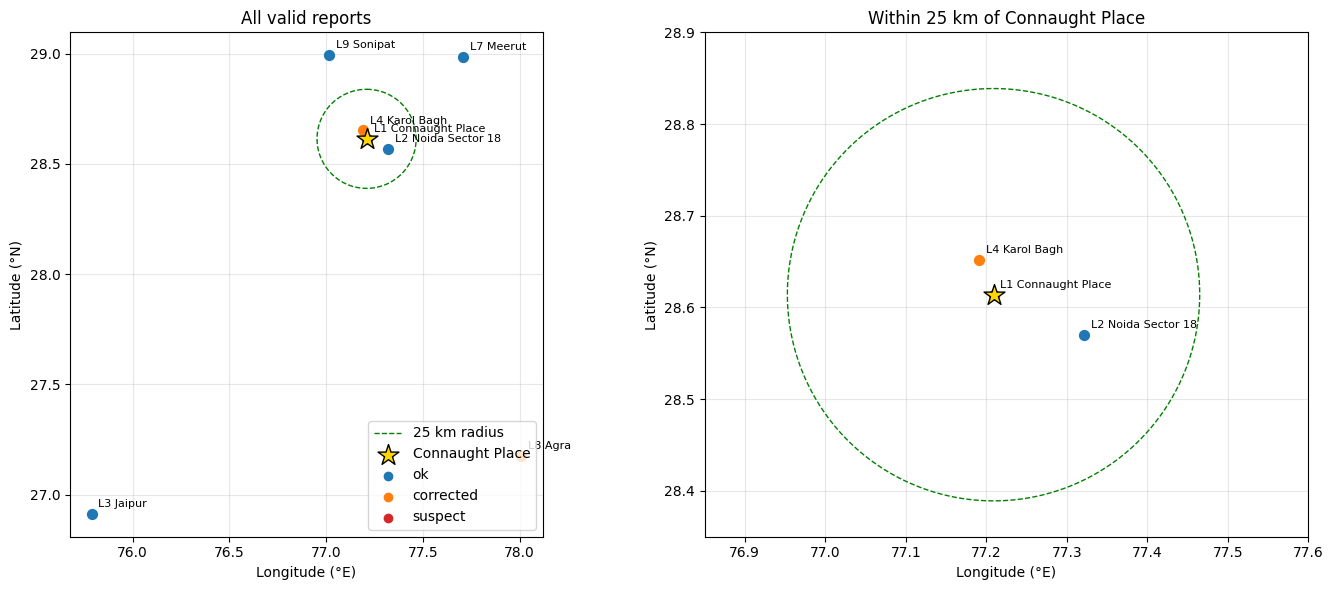

In [14]:
def destination(lat, lon, bearing_deg, dist_km):
    # Point at a given bearing and distance on the sphere (for drawing the 25 km circle).
    phi1, lam1, brg = math.radians(lat), math.radians(lon), math.radians(bearing_deg)
    d = dist_km / R_EARTH_KM
    phi2 = math.asin(math.sin(phi1) * math.cos(d) + math.cos(phi1) * math.sin(d) * math.cos(brg))
    lam2 = lam1 + math.atan2(math.sin(brg) * math.sin(d) * math.cos(phi1),
                             math.cos(d) - math.sin(phi1) * math.sin(phi2))
    return math.degrees(phi2), math.degrees(lam2)

colours = {"ok": "tab:blue", "corrected": "tab:orange", "suspect": "tab:red"}
circle = [destination(*CP, b, RADIUS_KM) for b in range(0, 361, 2)]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, title, zoom in [(axes[0], "All valid reports", False), (axes[1], "Within 25 km of Connaught Place", True)]:
    ax.plot([p[1] for p in circle], [p[0] for p in circle], "g--", lw=1, label="25 km radius")
    for r in valid.itertuples():
        ax.scatter(r.lon, r.lat, color=colours[r.status], s=50, zorder=3)
        ax.annotate(f"{r.id} {r.place.split(',')[0]}", (r.lon, r.lat), textcoords="offset points",
                    xytext=(5, 5), fontsize=8)
    ax.scatter(*CP[::-1], marker="*", s=250, color="gold", edgecolor="k", zorder=4, label="Connaught Place")
    ax.set_aspect(1 / math.cos(math.radians(CP[0])))     # equal ground distance on both axes
    ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)"); ax.set_title(title)
    ax.grid(alpha=.3)
    if zoom:
        ax.set_xlim(76.85, 77.6); ax.set_ylim(28.35, 28.9)

for s, c in colours.items():
    axes[0].scatter([], [], color=c, label=s)
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. Part C – Discussion: Elasticsearch

### 9.1 Field type: `geo_point`

Store the normalised WGS84 coordinate in a **`geo_point`** field. Elasticsearch indexes it with a BKD tree, which makes distance, bounding‑box and polygon queries fast. Next to it, keep:

* the **original string** (`location_raw`, `keyword`) so every value can be traced back to the source,
* the **detected format and grid zone** (`keyword`),
* a **quality status** (`ok` / `corrected` / `invalid`) and **notes**, so searches can include or exclude corrected data and analysts can see why a record has no location.

Records with no valid location (L5, L6) are still indexed, just **without** the `geo_point`. They stay searchable by text and will never match a distance query by accident.

`geo_shape` is for areas and lines. For single points, `geo_point` is simpler and faster.

In [15]:
mapping = {
    "mappings": {
        "properties": {
            "id":              {"type": "keyword"},
            "place":           {"type": "text", "fields": {"raw": {"type": "keyword"}}},
            "location":        {"type": "geo_point"},
            "location_raw":    {"type": "keyword"},
            "location_format": {"type": "keyword"},
            "grid_zone":       {"type": "keyword"},
            "location_status": {"type": "keyword"},
            "location_notes":  {"type": "text"},
        }
    }
}
print("PUT /locations_clean")
print(json.dumps(mapping, indent=2))

PUT /locations_clean
{
  "mappings": {
    "properties": {
      "id": {
        "type": "keyword"
      },
      "place": {
        "type": "text",
        "fields": {
          "raw": {
            "type": "keyword"
          }
        }
      },
      "location": {
        "type": "geo_point"
      },
      "location_raw": {
        "type": "keyword"
      },
      "location_format": {
        "type": "keyword"
      },
      "grid_zone": {
        "type": "keyword"
      },
      "location_status": {
        "type": "keyword"
      },
      "location_notes": {
        "type": "text"
      }
    }
  }
}


The bulk‑load body below is generated from the cleaned data, so it is exactly what would be indexed:

In [16]:
def to_es_doc(r):
    doc = {"id": r["id"], "place": r["place"], "location_raw": r["raw"],
           "location_format": r["format"], "grid_zone": r["zone"],
           "location_status": r["status"], "location_notes": r["notes"] or None}
    if pd.notna(r["lat"]):
        doc["location"] = {"lat": round(r["lat"], 6), "lon": round(r["lon"], 6)}   # ~0.1 m
    return {k: v for k, v in doc.items() if v is not None}

bulk_lines = []
for r in clean.to_dict("records"):
    bulk_lines.append(json.dumps({"index": {"_index": "locations_clean", "_id": r["id"]}}))
    bulk_lines.append(json.dumps(to_es_doc(r), ensure_ascii=False))
print("POST /_bulk")
print("\n".join(bulk_lines))

POST /_bulk
{"index": {"_index": "locations_clean", "_id": "L1"}}
{"id": "L1", "place": "Connaught Place, New Delhi", "location_raw": "28.6139, 77.2090", "location_format": "decimal_pair", "location_status": "ok", "location": {"lat": 28.6139, "lon": 77.209}}
{"index": {"_index": "locations_clean", "_id": "L2"}}
{"id": "L2", "place": "Noida Sector 18", "location_raw": "IIA E 3068101 N 1203024", "location_format": "grid", "grid_zone": "IIA", "location_status": "ok", "location": {"lat": 28.570003, "lon": 77.321}}
{"index": {"_index": "locations_clean", "_id": "L3"}}
{"id": "L3", "place": "Jaipur", "location_raw": "26°54'45\"N 75°47'14\"E", "location_format": "dms", "location_status": "ok", "location": {"lat": 26.9125, "lon": 75.787222}}
{"index": {"_index": "locations_clean", "_id": "L4"}}
{"id": "L4", "place": "Karol Bagh, New Delhi", "location_raw": "77.1909, 28.6519", "location_format": "decimal_pair", "location_status": "corrected", "location_notes": "Written as lon,lat: (77.1909, 28.

### 9.2 Query: reports within 25 km

A **`geo_distance`** filter, inside `bool.filter` because it is a yes/no condition and doesn't need relevance scoring, so it can be cached. The `_geo_distance` sort returns the nearest first and reports each distance in km. `distance_type: "arc"` (the default) is a great‑circle calculation, the same idea as the haversine method used in Part B.

In [17]:
query = {
    "query": {
        "bool": {
            "filter": [
                {"geo_distance": {"distance": "25km",
                                  "location": {"lat": CP[0], "lon": CP[1]}}}
            ]
        }
    },
    "sort": [
        {"_geo_distance": {"location": {"lat": CP[0], "lon": CP[1]},
                           "order": "asc", "unit": "km", "distance_type": "arc"}}
    ],
    "_source": ["id", "place", "location", "location_status"]
}
print("GET /locations_clean/_search")
print(json.dumps(query, indent=2))

# What Elasticsearch would return, worked out locally from the same documents:
print("\nExpected hits:", ", ".join(f"{r.id} ({r.haversine_km:.1f} km)" for r in near.itertuples()))

GET /locations_clean/_search
{
  "query": {
    "bool": {
      "filter": [
        {
          "geo_distance": {
            "distance": "25km",
            "location": {
              "lat": 28.6139,
              "lon": 77.209
            }
          }
        }
      ]
    }
  },
  "sort": [
    {
      "_geo_distance": {
        "location": {
          "lat": 28.6139,
          "lon": 77.209
        },
        "order": "asc",
        "unit": "km",
        "distance_type": "arc"
      }
    }
  ],
  "_source": [
    "id",
    "place",
    "location",
    "location_status"
  ]
}

Expected hits: L1 (0.0 km), L4 (4.6 km), L2 (12.0 km)


### 9.3 Convert when the data is loaded, or when it is queried?

**Convert when the data is loaded**, for these reasons:

1. **Elasticsearch can only search what it has indexed.** `geo_distance` works on `geo_point` fields. A grid string like `IIA E 3068101 N 1203024` can't be range‑ or distance‑searched. Converting at query time would mean pulling back *every* document and filtering in the application, which loses the index and doesn't scale.
2. **Do it once, not on every query.** The inverse projection and datum shift are iterative calculations. At load time they run once per record. At query time they would run for every record on every search.
3. **Consistent answers.** Every query, dashboard and aggregation sees the same coordinates. Converting at query time invites different clients to use different parameters (for example, forgetting the datum shift, or using the wrong Everest variant).
4. **Catch bad data on arrival.** The checks in A.6 (swapped axes, wrong zone, Null Island, missing values) should run when data enters the system, where problems can be logged, flagged and fixed. If they run silently at query time, bad records simply disappear from results.
5. **Nothing is lost.** Because the original string, format and zone are stored next to the `geo_point`, a better conversion later (for example, a more accurate 7‑parameter shift for India) only needs a **reindex**, an `_update_by_query`, or an **ingest pipeline** re‑run. No source data is lost.

In practice the conversion would go in the loading code or an Elasticsearch **ingest pipeline** (a script processor), so every route into the index gets the same treatment. Query time is only the better choice when the conversion parameters change often and the data is small, and neither is true here.

## 10. Summary

In [18]:
summary = clean[["id", "place", "raw", "format", "lat", "lon", "status", "notes"]].copy()
summary = summary.merge(valid[["id", "haversine_km", "within_25km"]], on="id", how="left")
summary["lat"] = summary["lat"].round(5); summary["lon"] = summary["lon"].round(5)
summary["haversine_km"] = summary["haversine_km"].round(2)
summary

,id,place,raw,format,lat,lon,status,notes,haversine_km,within_25km
0,L1,"Connaught Place, New Delhi","28.6139, 77.2090",decimal_pair,28.6139,77.20900,ok,,0.00,True
1,L2,Noida Sector 18,IIA E 3068101 N 1203024,grid,28.5700,77.32100,ok,,11.98,True
2,L3,Jaipur,"26°54'45""N 75°47'14""E",dms,26.9125,75.78722,ok,,235.29,False
3,L4,"Karol Bagh, New Delhi","77.1909, 28.6519",decimal_pair,28.6519,77.19090,corrected,"Written as lon,lat: (77.1909, 28.6519) read as lat,lon would be at latitude ...",4.58,True
4,L5,Unknown,"0, 0",decimal_pair,NaN,NaN,invalid,"(0, 0) is a placeholder ('Null Island', Gulf of Guinea), not a real location.",NaN,NaN
5,L6,Rohtak,None,missing,NaN,NaN,invalid,No location supplied (null).,NaN,NaN
6,L7,Meerut,"28.9845 N, 77.7064 E",hemisphere,28.9845,77.70640,ok,,63.62,False
7,L8,Agra,IIB E 3140017 N 1050679,grid,27.1767,78.00810,corrected,"As zone IIB it lands at (27.1770, 94.0060), 1,581 km from Agra. As zone IIA ...",178.06,False
8,L9,Sonipat,IIA E 3037105 N 1249178,grid,28.9931,77.01510,ok,,46.20,False


Save the cleaned table so other notebooks (for example **Geohash_Distance.ipynb**) can reuse it without repeating the conversion.

In [19]:
out = summary.drop(columns=["within_25km"]).rename(columns={"haversine_km": "km_from_cp"})
out.to_csv("locations_clean.csv", index=False)
print(f"Wrote locations_clean.csv ({len(out)} rows)")

Wrote locations_clean.csv (9 rows)


**Limitations**

* The 3‑parameter datum shift from the brief is a regional average, accurate to roughly tens of metres. That is fine for a 25 km search, but not good enough for survey work.
* The reference coordinates used in A.6 are approximate centres. They detect errors of kilometres, not metres.
* Reports carry no height, so $h = 0$ is assumed. The effect on horizontal position is negligible.